# HDBSCAN — Cosine


In [ ]:
import time
import tracemalloc
from pathlib import Path
import hdbscan
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, pairwise_distances
from sklearn.preprocessing import StandardScaler, Normalizer

default_data = next(
    (path for path in (Path("data/cafes.csv"), Path("cafes.csv")) if path.is_file()),
    Path("data/cafes.csv"),
)
DATA_PATH = Path(globals().get("DATA_PATH", default_data)).expanduser().resolve()
FIGURES_DIR = Path(globals().get("FIGURES_DIR", Path("reports/figures"))).expanduser().resolve()
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"CSV tidak ditemukan: {DATA_PATH}. Buka notebook dari folder paket "
        "atau tentukan DATA_PATH ke lokasi CSV Anda."
    )
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
# ==============================================================================
# BAGIAN A: LOAD DATA & PREPROCESSING (HDBSCAN)
# ==============================================================================
print("\n" + "="*56)
print("  BAGIAN A: LOAD DATA & PREPROCESSING (HDBSCAN)")
print("="*56)

df = pd.read_csv(DATA_PATH, on_bad_lines="skip")
kolom_fitur = ['latitude', 'longitude', 'rating', 'review_count']
kolom_ada = [k for k in kolom_fitur if k in df.columns]
df_fitur = df[kolom_ada].dropna()

# Standardisasi fitur numerik
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_fitur)

# L2 Normalization & Matriks Jarak Cosine
normalizer = Normalizer(norm='l2')
X_l2 = normalizer.fit_transform(X_scaled)
D_cosine = pairwise_distances(X_l2, metric='cosine').astype(np.float64)
np.fill_diagonal(D_cosine, 0.0)
D_cosine = np.clip(D_cosine, 0.0, 2.0)

print(f"Data siap | Shape: {X_scaled.shape} | Baris: {len(df_fitur)}")



  BAGIAN A: LOAD DATA & PREPROCESSING (HDBSCAN)
Data siap | Shape: (215, 4) | Baris: 215


In [3]:
MCS_COS = 4
MS_COS = 2

# --- 3. HDBSCAN COSINE ---
print("\n" + "="*56)
print("  HDBSCAN — METRIK: COSINE")
print(f"  Parameter: min_cluster_size={MCS_COS}, min_samples={MS_COS}")
print("="*56)

tracemalloc.start()
t_mulai = time.time()

hdb_cosine = hdbscan.HDBSCAN(
    min_cluster_size=MCS_COS, min_samples=MS_COS, metric='precomputed', gen_min_span_tree=True
)
lbl_cosine = hdb_cosine.fit_predict(D_cosine)

t_selesai = time.time()
_, mem_puncak = tracemalloc.get_traced_memory()
tracemalloc.stop()

n_klaster_c = len(set(lbl_cosine)) - (1 if -1 in lbl_cosine else 0)
n_noise_c = int((lbl_cosine == -1).sum())
pct_noise_c = n_noise_c / len(lbl_cosine) * 100
mask_valid_c = lbl_cosine != -1

if mask_valid_c.sum() > 1 and n_klaster_c >= 2:
    sil_cosine = silhouette_score(X_l2[mask_valid_c], lbl_cosine[mask_valid_c], metric='cosine')
    sil_c_str = f"{sil_cosine:.4f}"
else:
    sil_cosine = None
    sil_c_str = "N/A (klaster < 2)"

waktu_c = t_selesai - t_mulai
mem_c_kb = mem_puncak / 1024
mem_c_mb = mem_puncak / (1024**2)

print(f"  Jumlah Klaster    : {n_klaster_c}")
print(f"  Titik Noise (-1)  : {n_noise_c} ({pct_noise_c:.1f}%)")
print(f"  Waktu Eksekusi    : {waktu_c:.4f} detik")
print(f"  Memori Puncak     : {mem_c_kb:.2f} KB ({mem_c_mb:.4f} MB)")
print(f"  Silhouette Score  : {sil_c_str}")
print("="*56)



  HDBSCAN — METRIK: COSINE
  Parameter: min_cluster_size=4, min_samples=2
  Jumlah Klaster    : 20
  Titik Noise (-1)  : 64 (29.8%)
  Waktu Eksekusi    : 0.0308 detik
  Memori Puncak     : 938.84 KB (0.9168 MB)
  Silhouette Score  : 0.6298



  BAGIAN D: VISUALISASI PCA 2D (HDBSCAN)


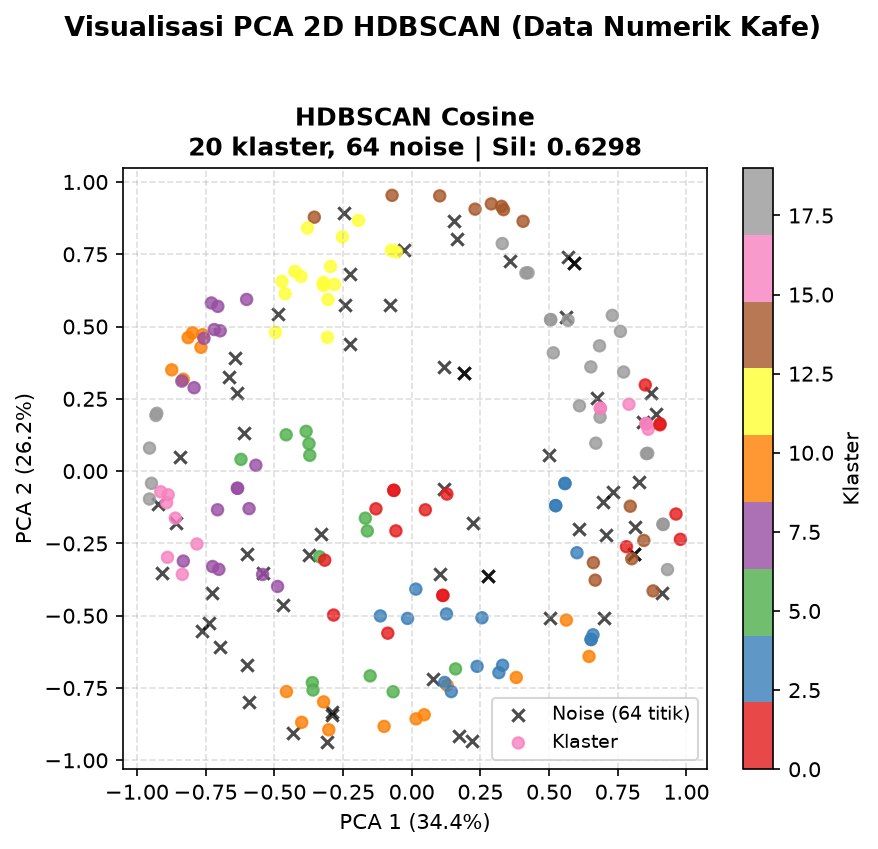

Visualisasi PCA disimpan ke: E:\Code\machine_learning\uts\reports\figures\hdbscan_cosine_pca_plots.png


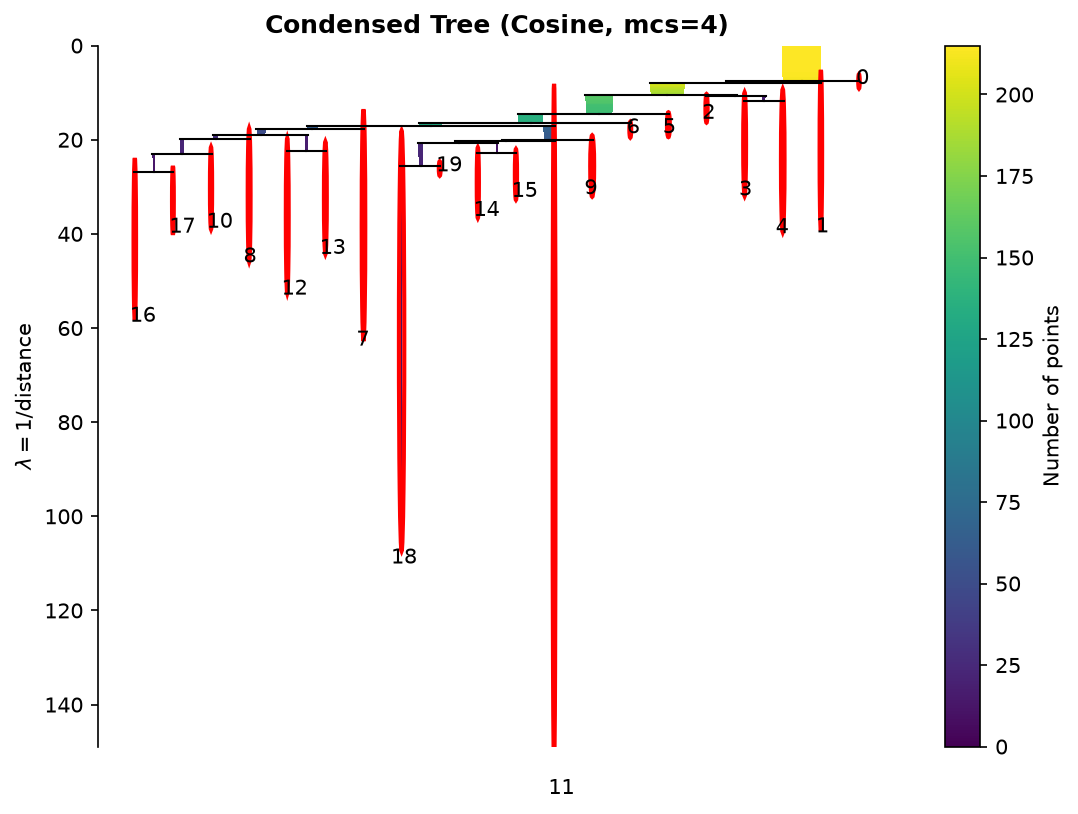

Condensed Tree plot disimpan ke: E:\Code\machine_learning\uts\reports\figures\hdbscan_cosine_condensed_tree.png


In [ ]:
def plot_condensed_tree_safe(model, ax):
    from matplotlib.patches import Ellipse
    from matplotlib.text import Annotation

    model.condensed_tree_.plot(axis=ax, select_clusters=True, label_clusters=True)
    for label in ax.texts:
        if isinstance(label, Annotation):
            label.xy = tuple(float(np.asarray(v).item()) for v in label.xy)
            label.set_position(tuple(float(np.asarray(v).item())
                                     for v in label.get_position()))
    for patch in ax.patches:
        if isinstance(patch, Ellipse):
            patch.set_width(float(np.asarray(patch.width).item()))
            patch.set_height(float(np.asarray(patch.height).item()))
    return ax


# ==============================================================================
# BAGIAN D: VISUALISASI PCA 2D & CONDENSED CLUSTER TREE
# ==============================================================================
print("\n" + "="*56)
print("  BAGIAN D: VISUALISASI PCA 2D (HDBSCAN)")
print("="*56)

pca_l2 = PCA(n_components=2, random_state=42)
X_pca_l2 = pca_l2.fit_transform(X_l2)
v1_l2, v2_l2 = pca_l2.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(6, 5.5), dpi=150)
axes = [ax]

def plot_hdbscan_pca(ax, X_pca_coords, lbls, v1, v2, title):
    mask_noise = lbls == -1
    mask_klaster = ~mask_noise

    # Plot titik noise -> hitam, tanda x
    ax.scatter(X_pca_coords[mask_noise, 0], X_pca_coords[mask_noise, 1],
               c='black', marker='x', s=35, alpha=0.7,
               label=f'Noise ({mask_noise.sum()} titik)')

    # Plot titik klaster -> berwarna
    if mask_klaster.sum() > 0:
        sc = ax.scatter(X_pca_coords[mask_klaster, 0], X_pca_coords[mask_klaster, 1],
                        c=lbls[mask_klaster], cmap='Set1', s=30, alpha=0.8,
                        label='Klaster')
        plt.colorbar(sc, ax=ax, label='Klaster')

    ax.set_title(title, fontweight='bold')
    ax.set_xlabel(f'PCA 1 ({v1:.1f}%)')
    ax.set_ylabel(f'PCA 2 ({v2:.1f}%)')
    ax.legend(fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.4)

plot_hdbscan_pca(axes[0], X_pca_l2, lbl_cosine, v1_l2, v2_l2,
                 f"HDBSCAN Cosine\n{n_klaster_c} klaster, {n_noise_c} noise | Sil: {sil_c_str}")

plt.suptitle("Visualisasi PCA 2D HDBSCAN (Data Numerik Kafe)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
hdb_pca_path = FIGURES_DIR / "hdbscan_cosine_pca_plots.png"
plt.savefig(hdb_pca_path, dpi=150, bbox_inches='tight')
plt.show()
plt.close()
print(f"Visualisasi PCA disimpan ke: {hdb_pca_path}")

fig, ax = plt.subplots(figsize=(7.5, 5.5), dpi=150)
axes = [ax]
plot_condensed_tree_safe(hdb_cosine, axes[0])
axes[0].set_title(f"Condensed Tree (Cosine, mcs={MCS_COS})", fontweight='bold')
axes[0].set_ylabel(r"$\lambda = 1 / \text{distance}$")

plt.tight_layout()
tree_plot_path = FIGURES_DIR / "hdbscan_cosine_condensed_tree.png"
plt.savefig(tree_plot_path, dpi=150)
plt.show()
plt.close()
print(f"Condensed Tree plot disimpan ke: {tree_plot_path}")


In [5]:
# Dictionary ringkasan performa untuk pelaporan
HDBSCAN_SUMMARY = {
    "cosine": {
        "algo": "HDBSCAN", "metric": "Cosine", "param": f"mcs={MCS_COS}, ms={MS_COS}",
        "time": waktu_c, "mem_mb": mem_c_mb, "clusters": n_klaster_c,
        "noise_pct": pct_noise_c, "silhouette": sil_cosine, "labels": lbl_cosine
    }
}
